# Model training and testing

Run this notebook from the `freight-rate-assessment` folder. Each function is in its own cell. The cells at the bottom train and test every model, draw the training and October charts, and save the prediction files.

Deleting `outputs` or `scorer_results` is fine. Running this notebook creates them again.

## Setup

In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

### Paths and settings

In [2]:
ROOT = Path.cwd()
if not (ROOT / "data" / "train_test.csv").exists():
    raise FileNotFoundError("Run this notebook from the freight-rate-assessment folder.")
DATA = ROOT / "data"
OUTPUT = ROOT / "outputs"
FIGURES = OUTPUT / "figures"
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

HOLDOUT_START = pd.Timestamp("2025-10-01")
EQUIPMENT_CODES = {"Dry Van": 0, "Reefer": 1, "Flatbed": 2}
CORE_FEATURES = [
    "distance", "log_distance", "weight_abs", "weight_missing", "weight_negative",
    "doy_sin", "doy_cos", "dow", "month", "pickup_lat", "pickup_lon",
    "delivery_lat", "delivery_lon", "equipment_code",
]
MARKET_FEATURES = ["market_index", "market_missing", "quote_signal"]
CATEGORICAL = ["equipment_code", "dow", "month"]
MODEL_PARAMS = dict(
    loss="absolute_error", learning_rate=0.06, max_iter=300, max_depth=8,
    min_samples_leaf=20, l2_regularization=0.1, random_state=42,
)
COLOR = "#064A56"
ACCENT = "#C46B4A"
LAG_FEATURES = ["rpm_lag_1", "rpm_lag_7"]
MATRIX_COLUMNS = [
    "distance", "weight_abs", "market_index", "quote_signal", "pickup_lat", "pickup_lon",
    "delivery_lat", "delivery_lon", "is_dry_van", "is_reefer", "is_flatbed", "dow", "month",
    "posted_rate", "rpm",
]
EXPECTED_ROWS = 12_000
EXPECTED_IDS = {f"TE-{index:06d}" for index in range(1, EXPECTED_ROWS + 1)}
DECEMBER_DATES = pd.date_range("2025-12-01", "2025-12-31", freq="D")
FIXED_PICKUP = "Lexington"
FIXED_DELIVERY = "Fort Wayne"
FIXED_DISTANCE = 360.0
FIXED_EQUIPMENT = "Dry Van"
FIXED_WEIGHT = 32_000.0

## Shared functions

### `regression_metrics`

In [3]:
def regression_metrics(actual: np.ndarray, predicted: np.ndarray) -> dict[str, float]:
    error = predicted - actual
    absolute = np.abs(error)
    percent = absolute / actual
    return {
        "mae": float(np.mean(absolute)),
        "rmse": float(np.sqrt(np.mean(error**2))),
        "mape": float(np.mean(percent)),
        "median_ae": float(np.median(absolute)),
        "r2": float(r2_score(actual, predicted)),
        "pct_over_25": float(np.mean(percent > 0.25)),
        "pct_over_50": float(np.mean(percent > 0.50)),
    }

### `city_coordinates`

In [4]:
def city_coordinates(labeled: pd.DataFrame) -> pd.DataFrame:
    pickup = labeled[["pickup", "pickup_lat", "pickup_lon"]].rename(
        columns={"pickup": "city", "pickup_lat": "lat", "pickup_lon": "lon"}
    )
    delivery = labeled[["delivery", "delivery_lat", "delivery_lon"]].rename(
        columns={"delivery": "city", "delivery_lat": "lat", "delivery_lon": "lon"}
    )
    coordinates = pd.concat([pickup, delivery], ignore_index=True).drop_duplicates()
    if coordinates["city"].duplicated().any():
        raise ValueError("a city has more than one coordinate pair")
    return coordinates

### `add_features`

In [5]:
def add_features(frame: pd.DataFrame, coordinates: pd.DataFrame | None = None) -> pd.DataFrame:
    features = frame.copy()
    features["date"] = pd.to_datetime(features["date"])
    if "pickup_lat" not in features.columns:
        if coordinates is None:
            raise ValueError("city coordinates are required when lat/lon are absent")
        features = features.merge(coordinates, left_on="pickup", right_on="city", how="left")
        features = features.rename(columns={"lat": "pickup_lat", "lon": "pickup_lon"}).drop(columns="city")
        features = features.merge(coordinates, left_on="delivery", right_on="city", how="left")
        features = features.rename(columns={"lat": "delivery_lat", "lon": "delivery_lon"}).drop(columns="city")
        if features[["pickup_lat", "delivery_lat"]].isna().any().any():
            raise ValueError("December cities are missing from the labeled coordinate table")

    weight = pd.to_numeric(features["weight"], errors="coerce")
    features["weight_missing"] = weight.isna().astype(np.int8)
    features["weight_negative"] = (weight < 0).fillna(False).astype(np.int8)
    features["weight_abs"] = weight.abs()

    if "market_index" not in features.columns:
        features["market_index"] = np.nan
    if "quote_signal" not in features.columns:
        features["quote_signal"] = np.nan
    features["market_missing"] = features["market_index"].isna().astype(np.int8)

    day_of_year = features["date"].dt.dayofyear.astype(float)
    features["doy_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
    features["doy_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)
    features["dow"] = features["date"].dt.dayofweek.astype(np.int8)
    features["month"] = features["date"].dt.month.astype(np.int8)
    features["log_distance"] = np.log(features["distance"].astype(float))
    unknown = set(features["equipment"].unique()) - set(EQUIPMENT_CODES)
    if unknown:
        raise ValueError(f"unexpected equipment types: {sorted(unknown)}")
    features["equipment_code"] = features["equipment"].map(EQUIPMENT_CODES).astype(np.int8)
    return features

### `make_model`

In [6]:
def make_model() -> HistGradientBoostingRegressor:
    return HistGradientBoostingRegressor(categorical_features=CATEGORICAL, **MODEL_PARAMS)

### `predict_rate`

In [7]:
def predict_rate(model: HistGradientBoostingRegressor, features: pd.DataFrame, columns: list[str]) -> np.ndarray:
    rate_per_mile = np.clip(model.predict(features[columns]), 0.05, None)
    return np.round(rate_per_mile * features["distance"].to_numpy(dtype=float), 2)

### `fit_mileage_baseline`

In [8]:
def fit_mileage_baseline(fit: pd.DataFrame) -> dict[str, LinearRegression]:
    models = {}
    for equipment, part in fit.groupby("equipment"):
        models[equipment] = LinearRegression().fit(part[["distance"]], part["posted_rate"])
    return models

### `predict_mileage_baseline`

In [9]:
def predict_mileage_baseline(models: dict[str, LinearRegression], frame: pd.DataFrame) -> np.ndarray:
    predicted = np.zeros(len(frame), dtype=float)
    for equipment, model in models.items():
        mask = frame["equipment"].eq(equipment).to_numpy()
        predicted[mask] = model.predict(frame.loc[mask, ["distance"]])
    return predicted

### `evaluate_feature_sets`

In [10]:
def evaluate_feature_sets(fit: pd.DataFrame, holdout: pd.DataFrame) -> tuple[list[str], dict[str, dict]]:
    """Pick the feature set with the lower October dollar error."""
    results = {}
    chosen_columns = CORE_FEATURES
    chosen_mae = np.inf
    sets = {
        "core": CORE_FEATURES,
        "core_plus_market": CORE_FEATURES + MARKET_FEATURES,
    }
    actual = holdout["posted_rate"].to_numpy(dtype=float)
    for name, columns in sets.items():
        model = make_model()
        model.fit(fit[columns], fit["posted_rate"] / fit["distance"])
        predicted = predict_rate(model, holdout, columns)
        metrics = regression_metrics(actual, predicted)
        results[name] = metrics
        print(
            f"{name:20} MAE {metrics['mae']:.2f}  RMSE {metrics['rmse']:.2f}  "
            f"MAPE {metrics['mape']:.4f}  median AE {metrics['median_ae']:.2f}"
        )
        if metrics["mae"] < chosen_mae:
            chosen_mae = metrics["mae"]
            chosen_columns = columns
    return chosen_columns, results

### `run_submission`

In [11]:
def run_submission() -> None:
    labeled = add_features(pd.read_csv(DATA / "train_test.csv"))
    validation = add_features(pd.read_csv(DATA / "validation.csv"))
    coordinates = city_coordinates(pd.read_csv(DATA / "train_test.csv"))
    december = add_features(pd.read_csv(DATA / "december_chart_inputs.csv"), coordinates)

    holdout_mask = labeled["date"] >= HOLDOUT_START
    fit = labeled.loc[~holdout_mask].copy()
    holdout = labeled.loc[holdout_mask].copy()
    print(f"Development rows: {len(fit):,} through {fit['date'].max():%Y-%m-%d}")
    print(f"October holdout:  {len(holdout):,}")

    baseline = fit_mileage_baseline(fit)
    baseline_prediction = predict_mileage_baseline(baseline, holdout)
    baseline_metrics = regression_metrics(holdout["posted_rate"].to_numpy(dtype=float), baseline_prediction)
    print(
        f"{'mileage baseline':20} MAE {baseline_metrics['mae']:.2f}  "
        f"RMSE {baseline_metrics['rmse']:.2f}  MAPE {baseline_metrics['mape']:.4f}"
    )

    chosen_columns, feature_results = evaluate_feature_sets(fit, holdout)
    chosen_name = "core_plus_market" if chosen_columns == CORE_FEATURES + MARKET_FEATURES else "core"
    print(f"Selected feature set: {chosen_name}")

    # The December chart has no market_index or quote_signal. If those features
    # are used, fill them with a typical labeled value instead of the rare
    # "field was blank" path the model learned from scattered missing cells.
    if "market_index" in chosen_columns:
        december["market_index"] = labeled["market_index"].median()
        december["quote_signal"] = labeled["quote_signal"].median()
        december["market_missing"] = np.int8(0)

    final_model = make_model()
    final_model.fit(labeled[chosen_columns], labeled["posted_rate"] / labeled["distance"])

    template = pd.read_csv(DATA / "validation_predictions_template.csv")
    validation_rates = predict_rate(final_model, validation, chosen_columns)
    predictions = validation[["load_id"]].copy()
    predictions["predicted_rate"] = validation_rates
    submitted = template[["load_id"]].merge(predictions, on="load_id", how="left", validate="one_to_one")
    if submitted["predicted_rate"].isna().any() or (submitted["predicted_rate"] <= 0).any():
        raise ValueError("validation predictions are incomplete or non-positive")
    prediction_path = ROOT / "validation_predictions.csv"
    submitted.to_csv(prediction_path, index=False)

    december_input = pd.read_csv(DATA / "december_chart_inputs.csv")
    december_rates = predict_rate(final_model, december, chosen_columns)
    december_output = december_input.copy()
    december_output["predicted_rate"] = december_rates
    if (december_output["predicted_rate"] <= 0).any():
        raise ValueError("December predictions must be positive")
    december_path = ROOT / "december_predictions.csv"
    december_output.to_csv(december_path, index=False)

    labeled_cities = set(coordinates["city"])
    validation_cities = set(validation["pickup"]) | set(validation["delivery"])
    metrics = {
        "holdout": "Train on 2025-01-01 through 2025-09-30. Score 2025-10-01 through 2025-10-31.",
        "holdout_rows": int(len(holdout)),
        "final_fit_rows": int(len(labeled)),
        "selected_features": chosen_name,
        "baseline": baseline_metrics,
        "models": feature_results,
        "selected_holdout": feature_results[chosen_name],
        "december_min": float(december_output["predicted_rate"].min()),
        "december_max": float(december_output["predicted_rate"].max()),
        "december_mean": float(december_output["predicted_rate"].mean()),
        "new_validation_cities": sorted(validation_cities - labeled_cities),
        "missing_weight_train": int(labeled["weight_missing"].sum()),
        "negative_weight_train": int(labeled["weight_negative"].sum()),
        "missing_market_index_train": int(labeled["market_missing"].sum()),
    }
    OUTPUT.mkdir(parents=True, exist_ok=True)
    (OUTPUT / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

    print(f"Wrote {prediction_path.name} ({len(submitted):,} rows)")
    print(f"Wrote {december_path.name} ({len(december_output):,} rows)")
    print(
        "December predicted rate "
        f"${metrics['december_min']:.2f} to ${metrics['december_max']:.2f} "
        f"(mean ${metrics['december_mean']:.2f})"
    )

## Time-series and comparison functions

### `style_axis`

In [12]:
def style_axis(axis: plt.Axes) -> None:
    axis.spines[["top", "right"]].set_visible(False)
    axis.spines[["left", "bottom"]].set_color("#9DAFB3")
    axis.grid(axis="y", color="#D9E2E4", linewidth=0.8)
    axis.set_axisbelow(True)

### `save`

In [13]:
def save(figure: plt.Figure, name: str) -> None:
    FIGURES.mkdir(parents=True, exist_ok=True)
    figure.tight_layout()
    figure.savefig(FIGURES / name, dpi=160, bbox_inches="tight")
    plt.close(figure)
    display(Image(filename=str(FIGURES / name)))

### `prepare`

In [14]:
def prepare() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    labeled = add_features(pd.read_csv(DATA / "train_test.csv"))
    labeled["rpm"] = labeled["posted_rate"] / labeled["distance"]
    labeled["is_dry_van"] = labeled["equipment"].eq("Dry Van").astype(float)
    labeled["is_reefer"] = labeled["equipment"].eq("Reefer").astype(float)
    labeled["is_flatbed"] = labeled["equipment"].eq("Flatbed").astype(float)
    fit = labeled.loc[labeled["date"] < HOLDOUT_START].copy()
    holdout = labeled.loc[labeled["date"] >= HOLDOUT_START].copy()
    return labeled, fit, holdout

### `daily_rpm`

In [15]:
def daily_rpm(frame: pd.DataFrame) -> pd.Series:
    series = frame.groupby(frame["date"].dt.normalize())["rpm"].median().sort_index()
    full_index = pd.date_range(series.index.min(), series.index.max(), freq="D")
    series = series.reindex(full_index)
    if series.isna().any():
        raise ValueError("the daily rate-per-mile series has gaps")
    series.index.name = "date"
    return series

### `equipment_factors`

In [16]:
def equipment_factors(fit: pd.DataFrame) -> pd.Series:
    equipment_median = fit.groupby("equipment")["rpm"].median()
    return equipment_median / fit["rpm"].median()

### `price_from_daily_rpm`

In [17]:
def price_from_daily_rpm(holdout: pd.DataFrame, forecast: pd.Series, factors: pd.Series) -> np.ndarray:
    daily = holdout["date"].dt.normalize().map(forecast)
    if daily.isna().any():
        raise ValueError("a holdout date is missing from the time-series forecast")
    factor = holdout["equipment"].map(factors)
    rate_per_mile = np.clip(daily.to_numpy(dtype=float) * factor.to_numpy(dtype=float), 0.05, None)
    return np.round(rate_per_mile * holdout["distance"].to_numpy(dtype=float), 2)

### `forecast_arima`

In [18]:
def forecast_arima(history: pd.Series, horizon: pd.DatetimeIndex) -> pd.Series:
    candidates = [(1, 1, 1), (2, 1, 1), (1, 1, 2), (2, 1, 2)]
    best_aic = np.inf
    best_order: tuple[int, int, int] | None = None
    best_model = None
    for order in candidates:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fitted = ARIMA(history, order=order).fit()
        if fitted.aic < best_aic:
            best_aic = float(fitted.aic)
            best_order = order
            best_model = fitted
    assert best_model is not None and best_order is not None
    print(f"ARIMA order {best_order}  AIC {best_aic:.1f}")
    forecast = best_model.forecast(steps=len(horizon))
    return pd.Series(np.asarray(forecast, dtype=float), index=horizon, name="arima")

### `dow_exog`

In [19]:
def dow_exog(index: pd.DatetimeIndex) -> pd.DataFrame:
    dummies = pd.get_dummies(pd.Series(index.dayofweek, index=index), prefix="dow", dtype=float)
    dummies = dummies.reindex(columns=[f"dow_{day}" for day in range(7)], fill_value=0.0)
    return dummies.drop(columns="dow_0")

### `forecast_sarimax`

In [20]:
def forecast_sarimax(history: pd.Series, horizon: pd.DatetimeIndex) -> pd.Series:
    train_exog = dow_exog(pd.DatetimeIndex(history.index))
    future_exog = dow_exog(horizon)
    candidates = [(1, 0, 1, 7), (1, 1, 0, 7), (0, 1, 1, 7)]
    best_aic = np.inf
    best_order = None
    best_model = None
    for seasonal in candidates:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fitted = SARIMAX(
                history,
                exog=train_exog,
                order=(1, 1, 1),
                seasonal_order=seasonal,
                enforce_stationarity=False,
                enforce_invertibility=False,
            ).fit(disp=False)
        if fitted.aic < best_aic:
            best_aic = float(fitted.aic)
            best_order = seasonal
            best_model = fitted
    assert best_model is not None and best_order is not None
    print(f"SARIMAX seasonal {best_order}  AIC {best_aic:.1f}")
    forecast = best_model.forecast(steps=len(horizon), exog=future_exog)
    return pd.Series(np.asarray(forecast, dtype=float), index=horizon, name="sarimax")

### `forecast_prophet`

In [21]:
def forecast_prophet(history: pd.Series, horizon: pd.DatetimeIndex) -> pd.Series:
    from prophet import Prophet

    frame = pd.DataFrame({"ds": history.index, "y": history.to_numpy()})
    model = Prophet(
        weekly_seasonality=True,
        yearly_seasonality=False,
        daily_seasonality=False,
        uncertainty_samples=0,
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(frame)
    future = pd.DataFrame({"ds": horizon})
    forecast = model.predict(future)
    return pd.Series(forecast["yhat"].to_numpy(dtype=float), index=horizon, name="prophet")

### `score_models`

In [22]:
def score_models(fit: pd.DataFrame, holdout: pd.DataFrame) -> tuple[dict[str, dict], pd.DataFrame]:
    actual = holdout["posted_rate"].to_numpy(dtype=float)
    scored: dict[str, dict] = {}

    baseline_prediction = predict_mileage_baseline(fit_mileage_baseline(fit), holdout)
    scored["mileage_baseline"] = regression_metrics(actual, baseline_prediction)

    boosting = make_model()
    boosting.fit(fit[CORE_FEATURES], fit["rpm"])
    scored["gradient_boosting"] = regression_metrics(actual, predict_rate(boosting, holdout, CORE_FEATURES))

    weight_median = float(fit["weight_abs"].median())
    forest_fit = fit[CORE_FEATURES].copy()
    forest_holdout = holdout[CORE_FEATURES].copy()
    forest_fit["weight_abs"] = forest_fit["weight_abs"].fillna(weight_median)
    forest_holdout["weight_abs"] = forest_holdout["weight_abs"].fillna(weight_median)
    forest = RandomForestRegressor(
        n_estimators=200,
        max_depth=16,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42,
    )
    forest.fit(forest_fit, fit["rpm"])
    forest_rpm = np.clip(forest.predict(forest_holdout), 0.05, None)
    forest_prediction = np.round(forest_rpm * holdout["distance"].to_numpy(dtype=float), 2)
    scored["random_forest"] = regression_metrics(actual, forest_prediction)

    history = daily_rpm(fit)
    horizon = pd.date_range("2025-10-01", "2025-10-31", freq="D")
    factors = equipment_factors(fit)
    forecasts = {
        "prophet": forecast_prophet(history, horizon),
        "arima": forecast_arima(history, horizon),
        "sarimax": forecast_sarimax(history, horizon),
    }
    for name, forecast in forecasts.items():
        scored[name] = regression_metrics(actual, price_from_daily_rpm(holdout, forecast, factors))

    actual_daily = daily_rpm(holdout)
    comparison = pd.DataFrame({"actual": actual_daily})
    for name, forecast in forecasts.items():
        comparison[name] = forecast
    return scored, comparison

### `comparison_charts`

In [23]:
def comparison_charts(scored: dict[str, dict], daily: pd.DataFrame) -> None:
    order = ["mileage_baseline", "gradient_boosting", "random_forest", "prophet", "arima", "sarimax"]
    labels = ["Mileage line", "Gradient boosting", "Random forest", "Prophet", "ARIMA", "SARIMAX"]
    mae = [scored[name]["mae"] for name in order]
    figure, axis = plt.subplots(figsize=(9.4, 4.8))
    colors = [COLOR if name == "gradient_boosting" else "#8AA4A8" for name in order]
    axis.bar(labels, mae, color=colors)
    axis.set_ylabel("October MAE ($)")
    axis.set_title("October score: lower dollar error is better", loc="left", fontsize=15, fontweight="bold")
    axis.tick_params(axis="x", rotation=20)
    style_axis(axis)
    save(figure, "model_comparison.png")

    figure, axis = plt.subplots(figsize=(10.4, 4.8))
    axis.plot(daily.index, daily["actual"], color="#1F2A2E", linewidth=2.4, label="Actual median")
    for name, color in (("prophet", COLOR), ("arima", ACCENT), ("sarimax", "#3D7A57")):
        axis.plot(daily.index, daily[name], linewidth=1.8, label=name.upper() if name != "prophet" else "Prophet")
    axis.set_ylabel("Median rate per mile ($)")
    axis.set_title("October daily rate per mile", loc="left", fontsize=15, fontweight="bold")
    axis.legend(frameon=False, ncol=4)
    style_axis(axis)
    save(figure, "october_daily_forecasts.png")

## Chart functions

### `record`

In [24]:
def record(name, train_pred, test_pred):
    train_score = regression_metrics(fit["posted_rate"].to_numpy(dtype=float), train_pred)
    test_score = regression_metrics(holdout["posted_rate"].to_numpy(dtype=float), test_pred)
    scores.append({"model": name, "train": train_score, "october": test_score})
    print(name)
    print(f"  training MAE ${train_score['mae']:.2f}   MAPE {train_score['mape']:.2%}")
    print(f"  October  MAE ${test_score['mae']:.2f}   MAPE {test_score['mape']:.2%}")
    return train_score, test_score

### `save_chart`

In [25]:
def save_chart(figure, title):
    folder = FIGURES / "models"
    folder.mkdir(parents=True, exist_ok=True)
    name = "".join(character.lower() if character.isalnum() else "_" for character in title).strip("_")
    path = folder / f"{name}.png"
    figure.savefig(path, dpi=140, bbox_inches="tight")
    plt.close(figure)
    display(Image(filename=str(path)))
    print("saved", path.relative_to(ROOT))

### `chart_load`

In [26]:
def chart_load(title, train_pred, test_pred):
    figure, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))
    rng = np.random.default_rng(42)
    sample = rng.choice(len(fit), size=min(2500, len(fit)), replace=False)
    panels = [
        (axes[0], fit["posted_rate"].to_numpy()[sample], np.asarray(train_pred)[sample], "Training sample"),
        (axes[1], holdout["posted_rate"].to_numpy(), np.asarray(test_pred), "October test"),
    ]
    for axis, actual, predicted, label in panels:
        axis.scatter(actual, predicted, s=8, alpha=0.22, color="#064A56", linewidths=0)
        top = float(np.quantile(np.concatenate([actual, predicted]), 0.98))
        axis.plot([0, top], [0, top], color="#C46B4A", linewidth=1.3)
        axis.set_xlim(0, top)
        axis.set_ylim(0, top)
        axis.set_title(label)
        axis.set_xlabel("Actual rate ($)")
        axis.set_ylabel("Predicted rate ($)")
        axis.spines[["top", "right"]].set_visible(False)
    train_mae = regression_metrics(fit["posted_rate"].to_numpy(dtype=float), train_pred)["mae"]
    test_mae = regression_metrics(holdout["posted_rate"].to_numpy(dtype=float), test_pred)["mae"]
    axes[2].bar(["Training", "October"], [train_mae, test_mae], color=["#064A56", "#C46B4A"])
    axes[2].set_ylabel("MAE ($)")
    axes[2].set_title("Error")
    axes[2].spines[["top", "right"]].set_visible(False)
    figure.suptitle(title, fontsize=14, fontweight="bold")
    figure.tight_layout()
    save_chart(figure, title)

### `align_fitted`

In [27]:
def align_fitted(values, index):
    series = pd.Series(np.asarray(values, dtype=float), dtype=float)
    if len(series) == len(index):
        series.index = index
    else:
        series.index = index[-len(series):]
        series = series.reindex(index).bfill()
    return series

### `chart_daily`

In [28]:
def chart_daily(title, fitted, forecast, train_pred, test_pred):
    figure, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
    axes[0].plot(history.index, history.to_numpy(), color="#1F2A2E", linewidth=1.4, label="Actual")
    axes[0].plot(fitted.index, fitted.to_numpy(), color="#064A56", linewidth=1.4, label="Training fit")
    axes[0].plot(october_actual.index, october_actual.to_numpy(), color="#3D7A57", linewidth=1.8, label="October actual")
    axes[0].plot(forecast.index, forecast.to_numpy(), color="#C46B4A", linewidth=1.8, label="October forecast")
    axes[0].set_title("Daily median rate per mile")
    axes[0].set_ylabel("Rate per mile ($)")
    axes[0].legend(frameon=False, fontsize=8)
    axes[0].spines[["top", "right"]].set_visible(False)
    train_mae = regression_metrics(fit["posted_rate"].to_numpy(dtype=float), train_pred)["mae"]
    test_mae = regression_metrics(holdout["posted_rate"].to_numpy(dtype=float), test_pred)["mae"]
    axes[1].bar(["Training", "October"], [train_mae, test_mae], color=["#064A56", "#C46B4A"])
    axes[1].set_ylabel("Dollar MAE ($)")
    axes[1].set_title("Load-level error")
    axes[1].spines[["top", "right"]].set_visible(False)
    figure.suptitle(title, fontsize=14, fontweight="bold")
    figure.tight_layout()
    save_chart(figure, title)

## Checker

### `fail`

In [29]:
def fail(message: str) -> None:
    raise SystemExit(f"ERROR: {message}")

### `read_csv`

In [30]:
def read_csv(path: Path, label: str) -> pd.DataFrame:
    if not path.is_file():
        fail(f"{label} file not found: {path}")
    try:
        return pd.read_csv(path)
    except Exception as exc:
        fail(f"could not read {label}: {exc}")

### `numeric_series`

In [31]:
def numeric_series(frame: pd.DataFrame, column: str, label: str) -> pd.Series:
    values = pd.to_numeric(frame[column], errors="coerce")
    if values.isna().any() or not np.isfinite(values).all():
        fail(f"{label} contains invalid {column} values")
    return values.astype(float)

### `validate_predictions`

In [32]:
def validate_predictions(predictions: pd.DataFrame) -> None:
    if list(predictions.columns) != ["load_id", "predicted_rate"]:
        fail("predictions must contain exactly two columns in this order: load_id,predicted_rate")
    if len(predictions) != EXPECTED_ROWS:
        fail(f"predictions must contain exactly {EXPECTED_ROWS:,} rows")
    if predictions["load_id"].isna().any() or predictions["load_id"].duplicated().any():
        fail("predictions contains missing or duplicate load_id values")

    submitted_ids = set(predictions["load_id"].astype(str))
    missing = EXPECTED_IDS - submitted_ids
    extra = submitted_ids - EXPECTED_IDS
    if missing or extra:
        fail(
            "prediction IDs do not match the validation set "
            f"(missing={len(missing)}, extra={len(extra)})"
        )

    predicted_rate = numeric_series(predictions, "predicted_rate", "predictions")
    if (predicted_rate <= 0).any():
        fail("predictions contains non-positive predicted_rate values")

### `validate_december`

In [33]:
def validate_december(frame: pd.DataFrame) -> pd.DataFrame:
    columns = ["pickup", "delivery", "distance", "equipment", "weight", "date", "predicted_rate"]
    if list(frame.columns) != columns:
        fail("December predictions must keep the original seven columns and column order")

    result = frame.copy()
    result["date"] = pd.to_datetime(result["date"], errors="coerce")
    if result["date"].isna().any():
        fail("December predictions contains invalid dates")
    result["distance"] = numeric_series(result, "distance", "December predictions")
    result["weight"] = numeric_series(result, "weight", "December predictions")
    result["predicted_rate"] = numeric_series(result, "predicted_rate", "December predictions")

    if result["date"].duplicated().any():
        fail("December predictions contains duplicate dates")
    if len(result) != 31 or set(result["date"]) != set(DECEMBER_DATES):
        fail("December predictions must contain one row for every day from 2025-12-01 to 2025-12-31")
    if not result["pickup"].eq(FIXED_PICKUP).all():
        fail(f"December pickup must be {FIXED_PICKUP} for all rows")
    if not result["delivery"].eq(FIXED_DELIVERY).all():
        fail(f"December delivery must be {FIXED_DELIVERY} for all rows")
    if not np.isclose(result["distance"], FIXED_DISTANCE).all():
        fail(f"December distance must be {FIXED_DISTANCE:g} for all rows")
    if not result["equipment"].eq(FIXED_EQUIPMENT).all():
        fail(f"December equipment must be {FIXED_EQUIPMENT} for all rows")
    if not np.isclose(result["weight"], FIXED_WEIGHT).all():
        fail(f"December weight must be {FIXED_WEIGHT:g} for all rows")
    if (result["predicted_rate"] <= 0).any():
        fail("December predicted_rate values must be positive")
    return result.sort_values("date")

### `save_december_chart`

In [34]:
def save_december_chart(december: pd.DataFrame, output: Path) -> None:
    figure, axis = plt.subplots(figsize=(10.8, 4.8), dpi=180)
    color = "#064A56"
    axis.plot(
        december["date"],
        december["predicted_rate"],
        color=color,
        linewidth=2.6,
        marker="o",
        markersize=3.2,
    )
    floor = float(december["predicted_rate"].min())
    axis.fill_between(
        december["date"],
        december["predicted_rate"],
        floor - max(10.0, floor * 0.02),
        color=color,
        alpha=0.08,
    )
    axis.set_title("Candidate: December 2025 Predicted Load Rate", loc="left", fontsize=15, fontweight="bold", pad=12)
    axis.set_ylabel("Predicted rate ($)")
    axis.grid(axis="y", color="#D9E2E4", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
    axis.spines[["left", "bottom"]].set_color("#9DAFB3")
    axis.tick_params(axis="x", rotation=35)
    axis.text(
        0,
        -0.40,
        "Fixed inputs: Lexington to Fort Wayne | 360 miles | Dry Van | 32,000 lb | only date changes",
        transform=axis.transAxes,
        fontsize=9.5,
        color="#455A60",
    )
    figure.tight_layout(rect=(0, 0.12, 1, 1))
    figure.savefig(output, bbox_inches="tight")
    plt.close(figure)
    display(Image(filename=str(output)))

### `run_scorer`

In [35]:
def run_scorer(predictions_path, december_path, output_dir="scorer_results"):
    validate_predictions(read_csv(Path(predictions_path), "predictions"))
    december = validate_december(read_csv(Path(december_path), "December predictions"))
    output = Path(output_dir)
    if not output.is_absolute():
        output = ROOT / output
    output.mkdir(parents=True, exist_ok=True)
    chart = output / "candidate_december.png"
    save_december_chart(december, chart)
    print(f"Validated {EXPECTED_ROWS:,} final predictions.")
    print("Validated 31 fixed December predictions.")
    print(f"Created chart: {chart}")
    print("Final validation metrics are calculated by Spotter after submission.")

## Run: write the submitted prediction files

In [36]:
run_submission()

Development rows: 43,147 through 2025-09-30
October holdout:  4,853
mileage baseline     MAE 147.43  RMSE 653.67  MAPE 0.0840
core                 MAE 115.50  RMSE 651.11  MAPE 0.0531  median AE 38.53
core_plus_market     MAE 128.16  RMSE 652.74  MAPE 0.0611  median AE 49.84
Selected feature set: core
Wrote validation_predictions.csv (12,000 rows)
Wrote december_predictions.csv (31 rows)
December predicted rate $787.49 to $812.02 (mean $799.08)


## Run: split January–September from October

In [37]:
labeled, fit, holdout = prepare()
print(f'training rows {len(fit):,}')
print(f'October rows  {len(holdout):,}')
scores = []

training rows 43,147
October rows  4,853


## Mileage line

Mileage line
  training MAE $153.97   MAPE 8.34%
  October  MAE $147.43   MAPE 8.40%


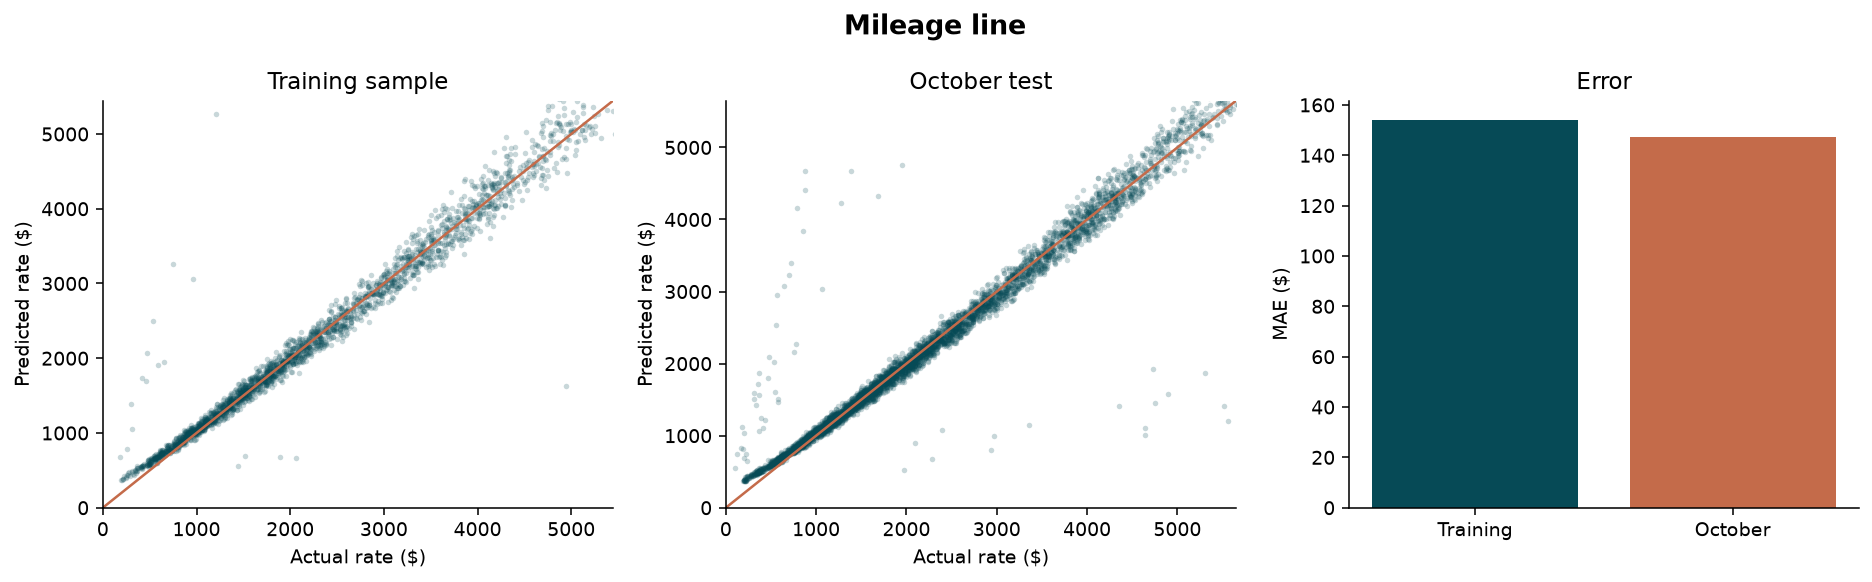

saved outputs\figures\models\mileage_line.png


In [38]:
mileage_models = fit_mileage_baseline(fit)
mileage_train_pred = predict_mileage_baseline(mileage_models, fit)
mileage_test_pred = predict_mileage_baseline(mileage_models, holdout)
record('Mileage line', mileage_train_pred, mileage_test_pred)
chart_load('Mileage line', mileage_train_pred, mileage_test_pred)

## Gradient boosting

Gradient boosting
  training MAE $80.65   MAPE 3.67%
  October  MAE $115.50   MAPE 5.31%


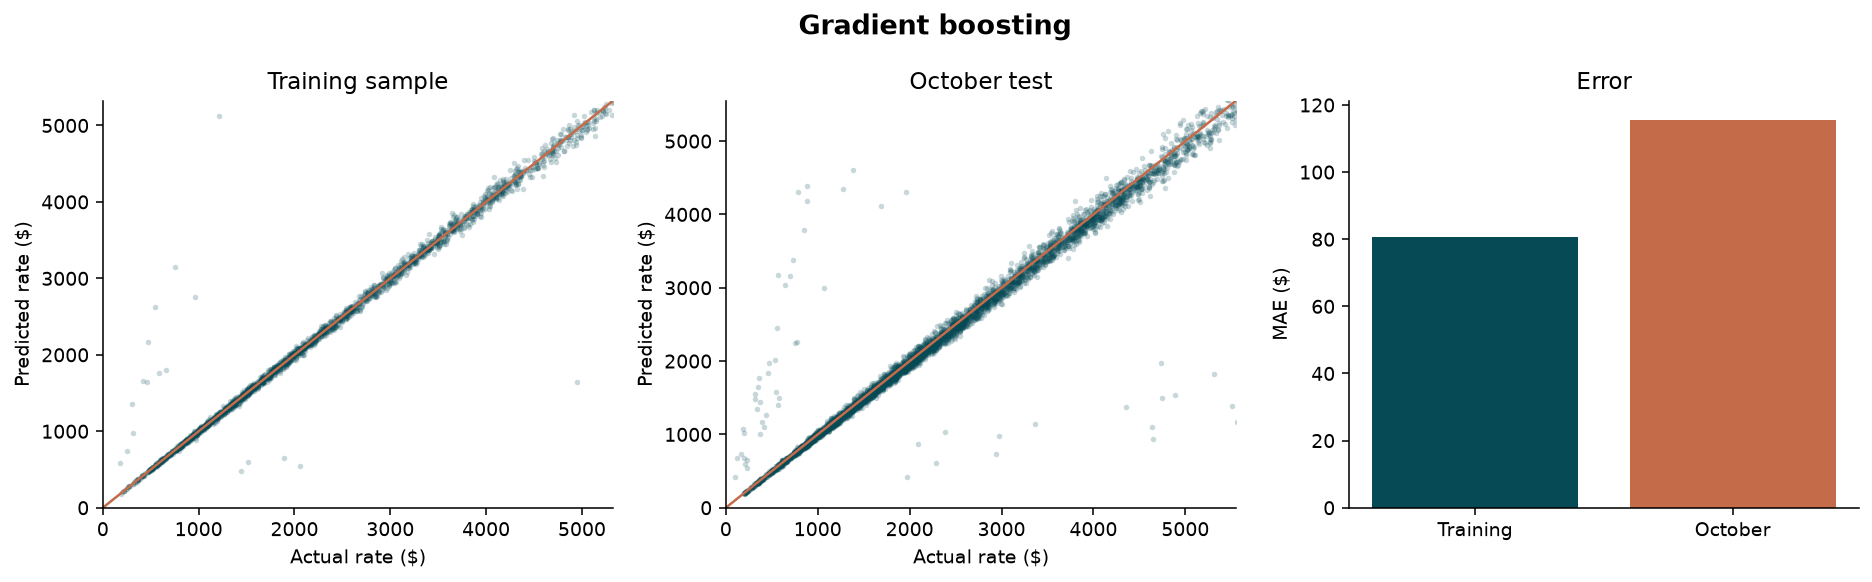

saved outputs\figures\models\gradient_boosting.png


In [39]:
boosting = make_model()
boosting.fit(fit[CORE_FEATURES], fit['rpm'])
boosting_train_pred = predict_rate(boosting, fit, CORE_FEATURES)
boosting_test_pred = predict_rate(boosting, holdout, CORE_FEATURES)
record('Gradient boosting', boosting_train_pred, boosting_test_pred)
chart_load('Gradient boosting', boosting_train_pred, boosting_test_pred)

## Random forest

Random forest
  training MAE $93.53   MAPE 4.27%
  October  MAE $143.55   MAPE 6.64%


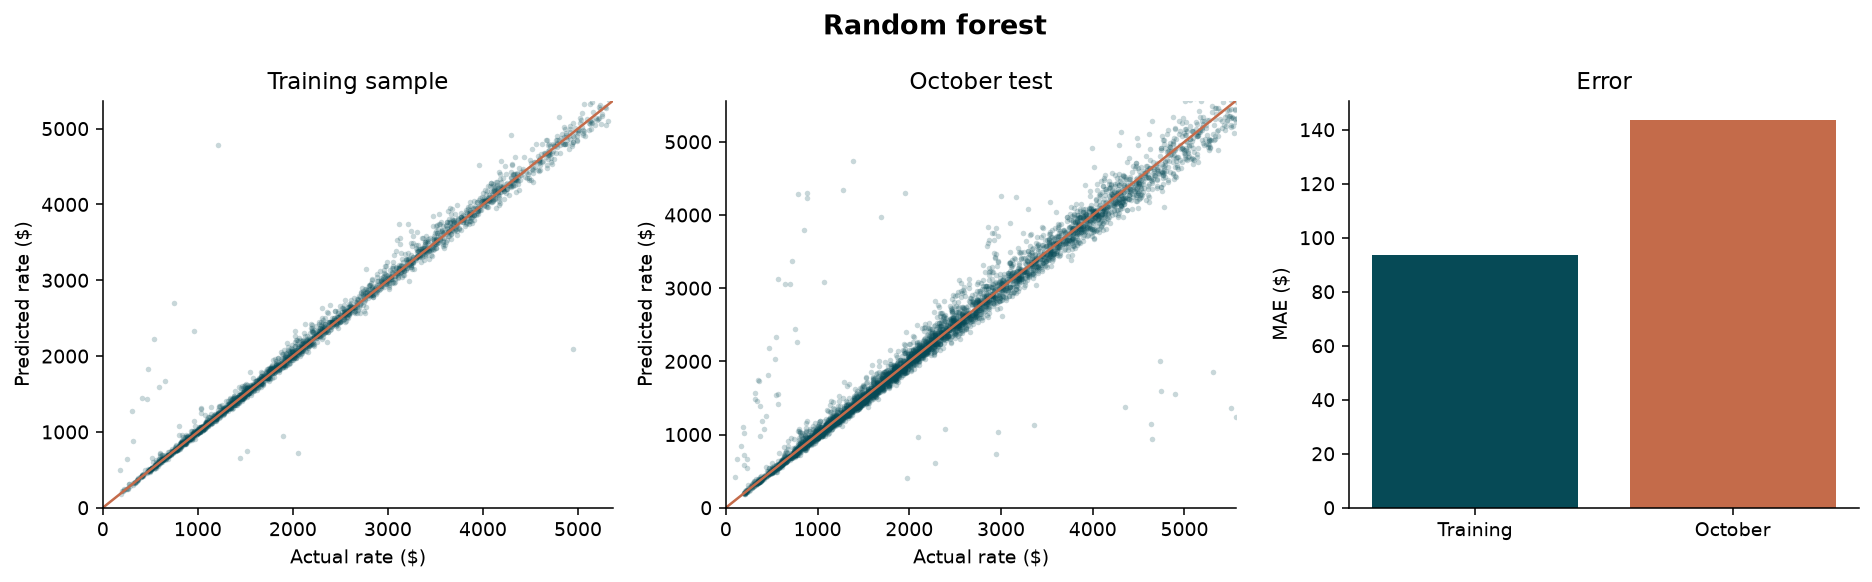

saved outputs\figures\models\random_forest.png


In [40]:
weight_median = float(fit["weight_abs"].median())
forest_train = fit[CORE_FEATURES].copy()
forest_test = holdout[CORE_FEATURES].copy()
forest_train["weight_abs"] = forest_train["weight_abs"].fillna(weight_median)
forest_test["weight_abs"] = forest_test["weight_abs"].fillna(weight_median)
forest = RandomForestRegressor(n_estimators=200, max_depth=16, min_samples_leaf=5, n_jobs=-1, random_state=42)
forest.fit(forest_train, fit["rpm"])
forest_train_pred = np.round(np.clip(forest.predict(forest_train), 0.05, None) * fit["distance"].to_numpy(dtype=float), 2)
forest_test_pred = np.round(np.clip(forest.predict(forest_test), 0.05, None) * holdout["distance"].to_numpy(dtype=float), 2)
record("Random forest", forest_train_pred, forest_test_pred)
chart_load("Random forest", forest_train_pred, forest_test_pred)

## Daily series used by Prophet, ARIMA, and SARIMAX

In [41]:
history = daily_rpm(fit)
horizon = pd.date_range('2025-10-01', '2025-10-31', freq='D')
factors = equipment_factors(fit)
october_actual = daily_rpm(holdout)
print(f'daily training points {len(history)}')

daily training points 273


## Prophet

d:\projects\SchoolProject\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.
15:32:18 - cmdstanpy - INFO - Chain [1] start processing
15:32:18 - cmdstanpy - INFO - Chain [1] done processing


Prophet
  training MAE $224.69   MAPE 10.07%
  October  MAE $259.66   MAPE 11.26%


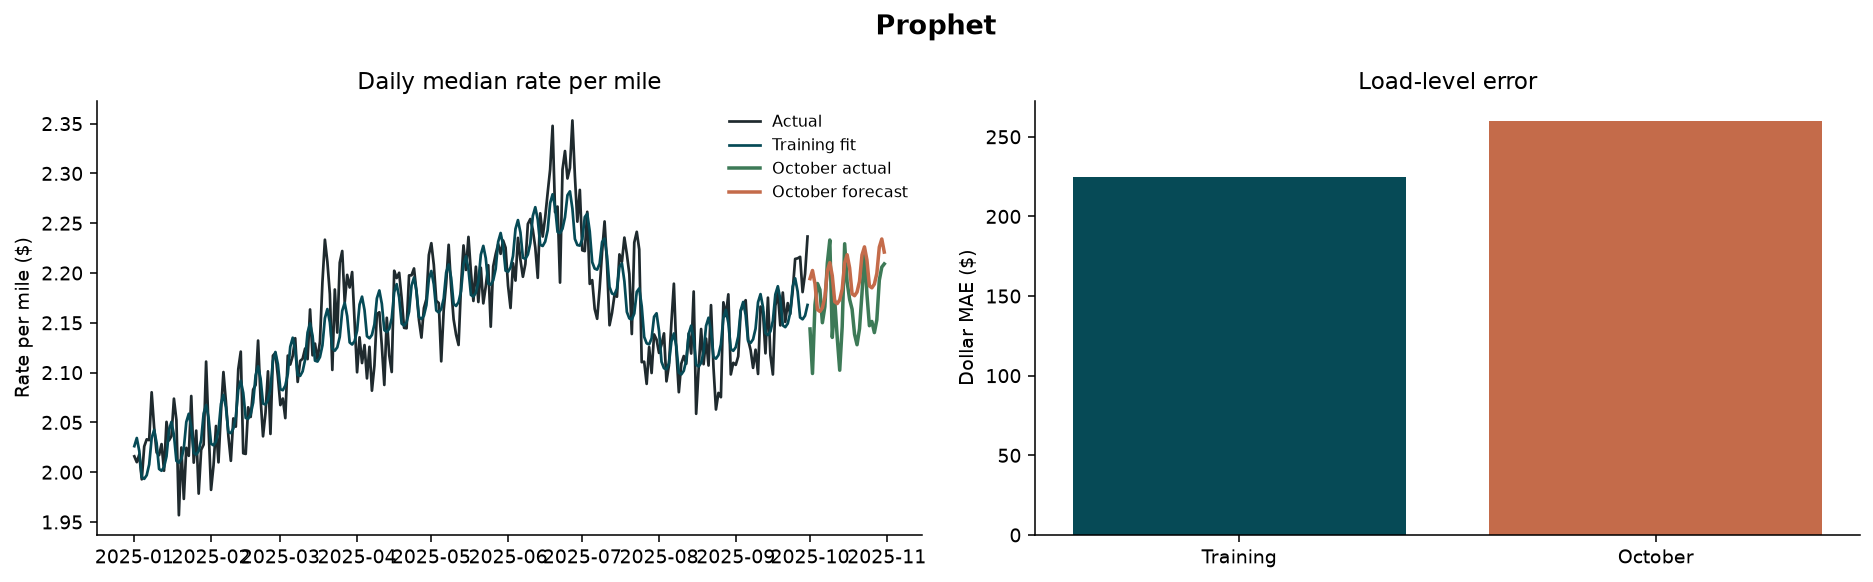

saved outputs\figures\models\prophet.png


In [42]:
from prophet import Prophet
prophet_frame = pd.DataFrame({"ds": history.index, "y": history.to_numpy()})
prophet_model = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False, uncertainty_samples=0)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    prophet_model.fit(prophet_frame)
prophet_fitted = prophet_model.predict(prophet_frame)
prophet_fit_series = pd.Series(prophet_fitted["yhat"].to_numpy(dtype=float), index=history.index)
prophet_future = prophet_model.predict(pd.DataFrame({"ds": horizon}))
prophet_forecast = pd.Series(prophet_future["yhat"].to_numpy(dtype=float), index=horizon)
prophet_train_pred = price_from_daily_rpm(fit, prophet_fit_series, factors)
prophet_test_pred = price_from_daily_rpm(holdout, prophet_forecast, factors)
record("Prophet", prophet_train_pred, prophet_test_pred)
chart_daily("Prophet", prophet_fit_series, prophet_forecast, prophet_train_pred, prophet_test_pred)

## ARIMA

ARIMA(1, 1, 1)  AIC -1034.8
ARIMA
  training MAE $230.37   MAPE 10.37%
  October  MAE $265.17   MAPE 11.37%


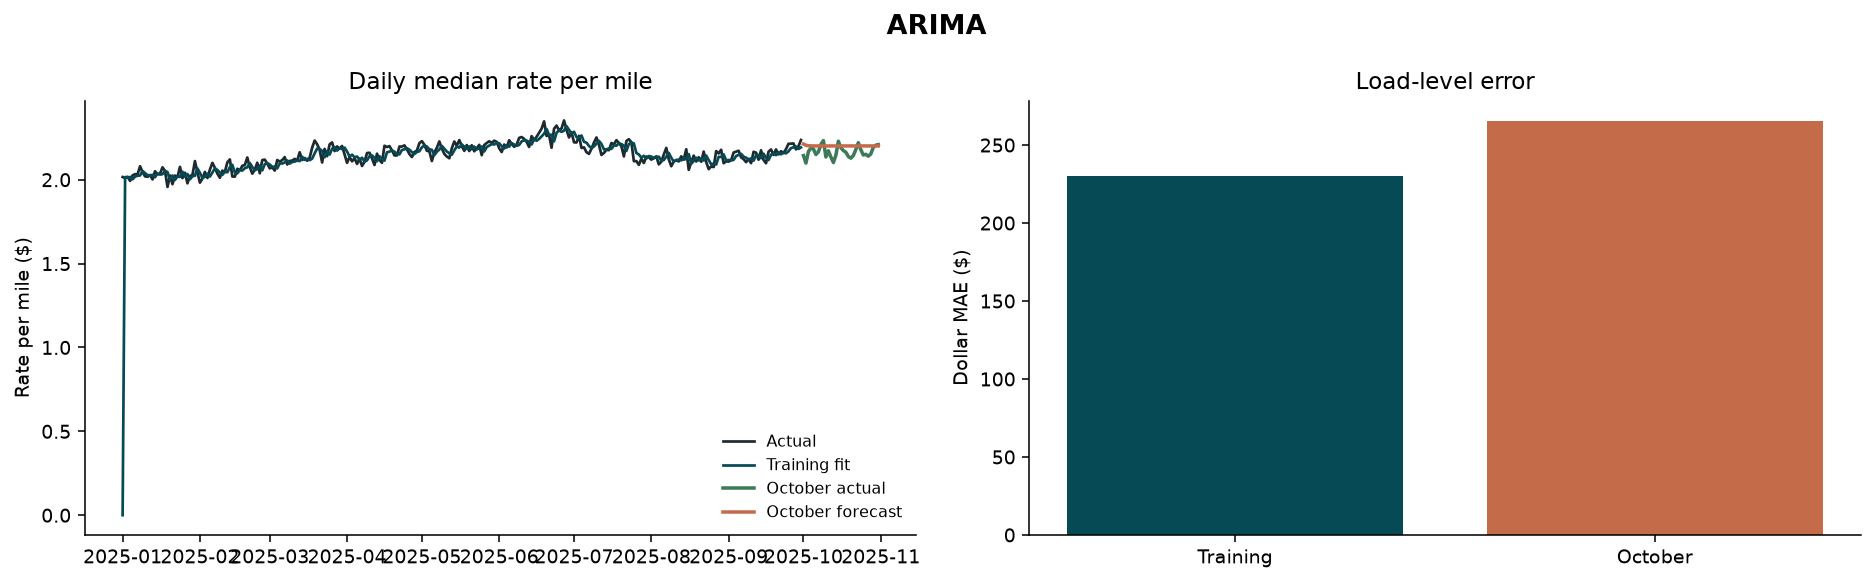

saved outputs\figures\models\arima.png


In [43]:
arima_orders = [(1, 1, 1), (2, 1, 1), (1, 1, 2), (2, 1, 2)]
arima_model = None
arima_order = None
arima_aic = np.inf
for order in arima_orders:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fitted = ARIMA(history, order=order).fit()
    if fitted.aic < arima_aic:
        arima_aic = float(fitted.aic)
        arima_order = order
        arima_model = fitted
arima_fit_series = align_fitted(arima_model.fittedvalues, history.index)
arima_forecast = pd.Series(np.asarray(arima_model.forecast(steps=len(horizon)), dtype=float), index=horizon)
arima_train_pred = price_from_daily_rpm(fit, arima_fit_series, factors)
arima_test_pred = price_from_daily_rpm(holdout, arima_forecast, factors)
print(f"ARIMA{arima_order}  AIC {arima_aic:.1f}")
record("ARIMA", arima_train_pred, arima_test_pred)
chart_daily("ARIMA", arima_fit_series, arima_forecast, arima_train_pred, arima_test_pred)

## SARIMAX

SARIMAX seasonal (1, 0, 1, 7)  AIC -1049.8
SARIMAX
  training MAE $230.01   MAPE 10.35%
  October  MAE $279.25   MAPE 11.63%


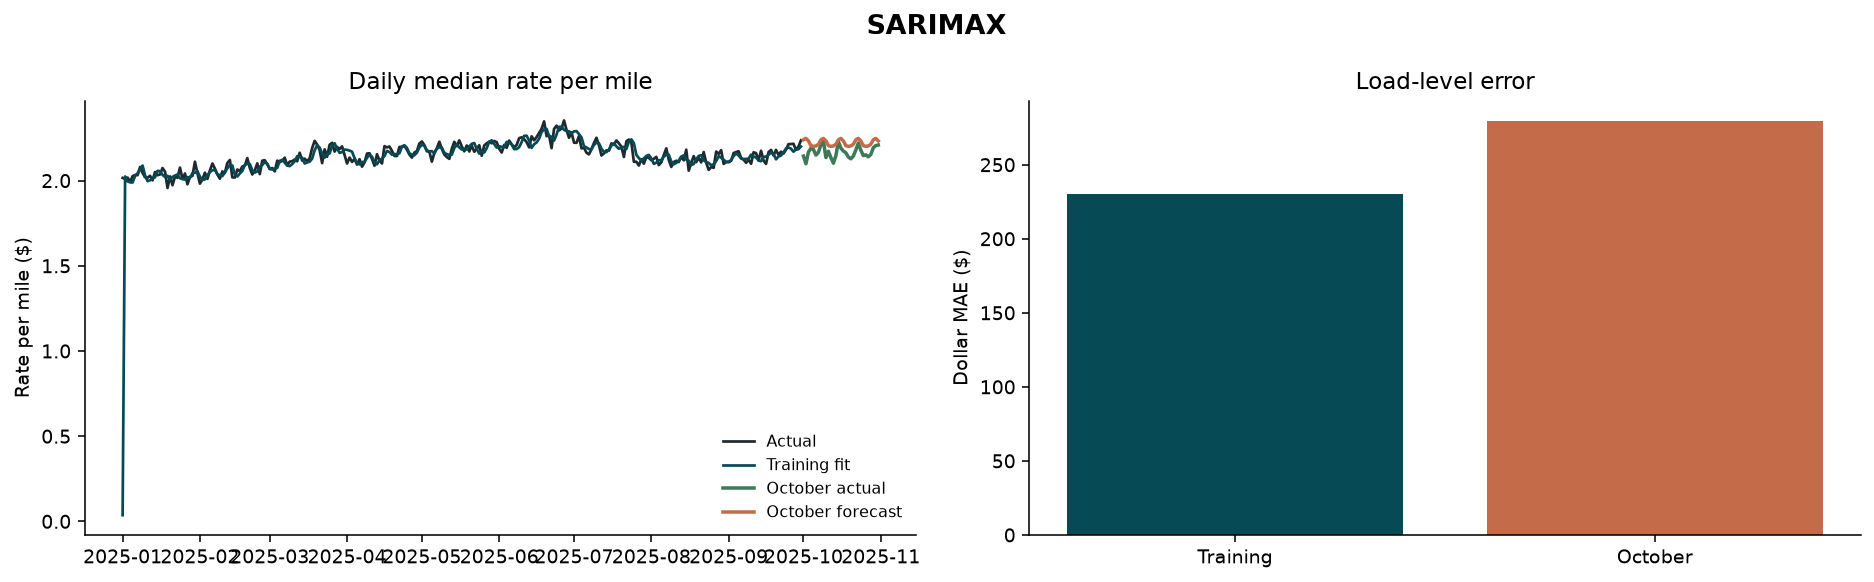

saved outputs\figures\models\sarimax.png


In [44]:
sarimax_train_exog = dow_exog(pd.DatetimeIndex(history.index))
sarimax_orders = [(1, 0, 1, 7), (1, 1, 0, 7), (0, 1, 1, 7)]
sarimax_model = None
sarimax_order = None
sarimax_aic = np.inf
for seasonal in sarimax_orders:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fitted = SARIMAX(
            history, exog=sarimax_train_exog, order=(1, 1, 1), seasonal_order=seasonal,
            enforce_stationarity=False, enforce_invertibility=False,
        ).fit(disp=False)
    if fitted.aic < sarimax_aic:
        sarimax_aic = float(fitted.aic)
        sarimax_order = seasonal
        sarimax_model = fitted
sarimax_fit_series = align_fitted(sarimax_model.fittedvalues, history.index)
sarimax_forecast = pd.Series(np.asarray(sarimax_model.forecast(steps=len(horizon), exog=dow_exog(horizon)), dtype=float), index=horizon)
sarimax_train_pred = price_from_daily_rpm(fit, sarimax_fit_series, factors)
sarimax_test_pred = price_from_daily_rpm(holdout, sarimax_forecast, factors)
print(f"SARIMAX seasonal {sarimax_order}  AIC {sarimax_aic:.1f}")
record("SARIMAX", sarimax_train_pred, sarimax_test_pred)
chart_daily("SARIMAX", sarimax_fit_series, sarimax_forecast, sarimax_train_pred, sarimax_test_pred)

## Compare every model and save the scorecard

,train_mae,october_mae,train_mape,october_mape
model,,,,
Mileage line,153.97,147.43,0.08,0.08
Gradient boosting,80.65,115.50,0.04,0.05
Random forest,93.53,143.55,0.04,0.07
Prophet,224.69,259.66,0.10,0.11
ARIMA,230.37,265.17,0.10,0.11
SARIMAX,230.01,279.25,0.10,0.12


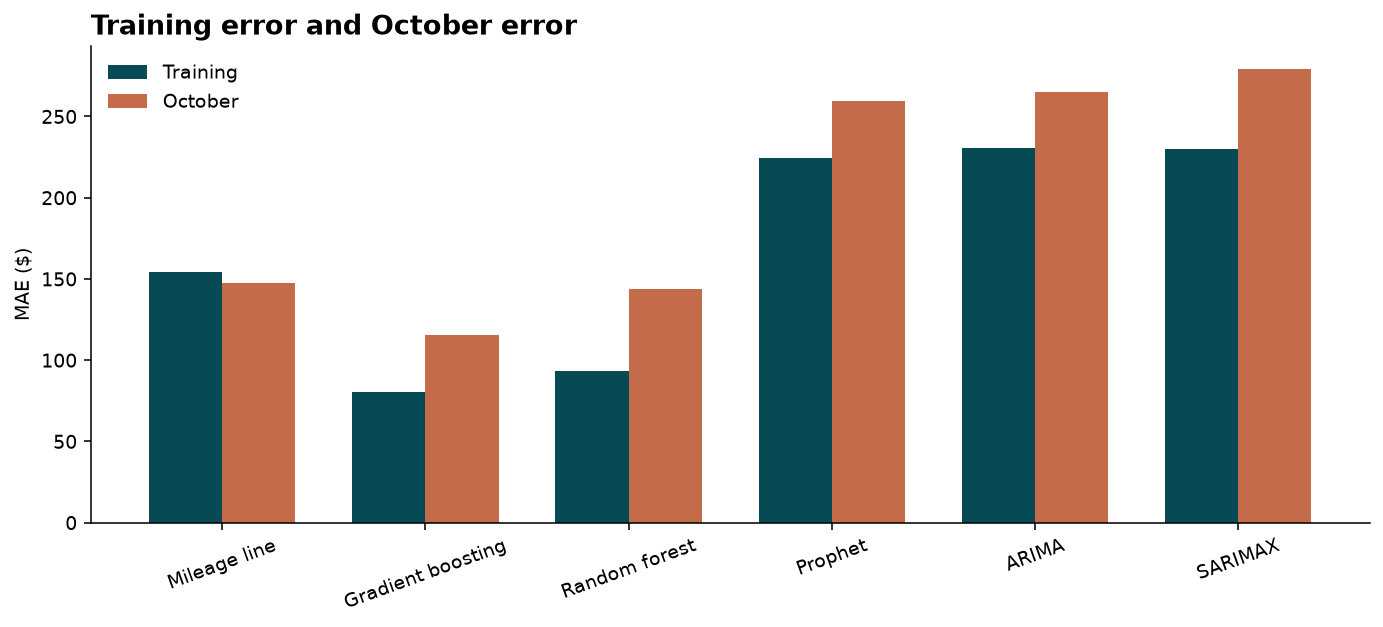

saved outputs\figures\models\all_models_train_versus_october.png


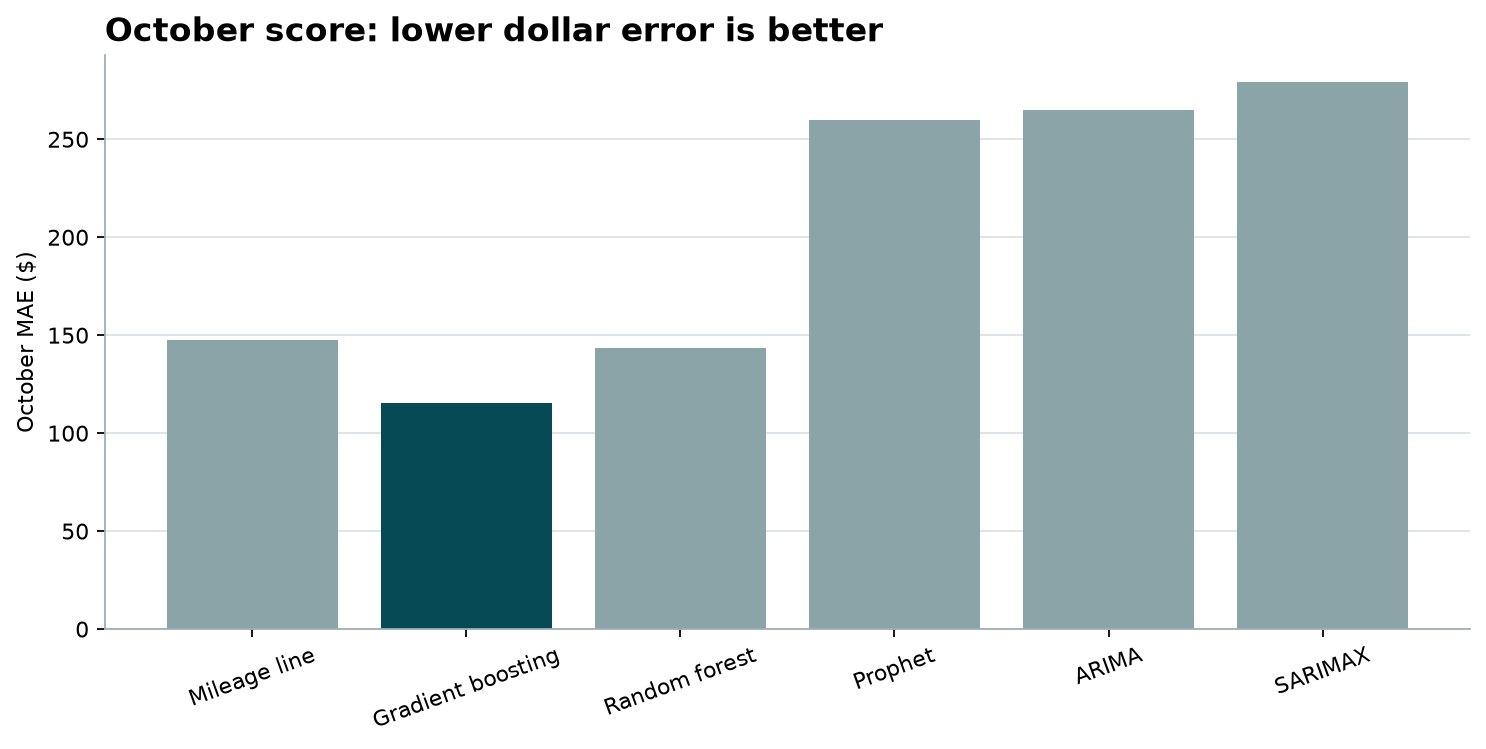

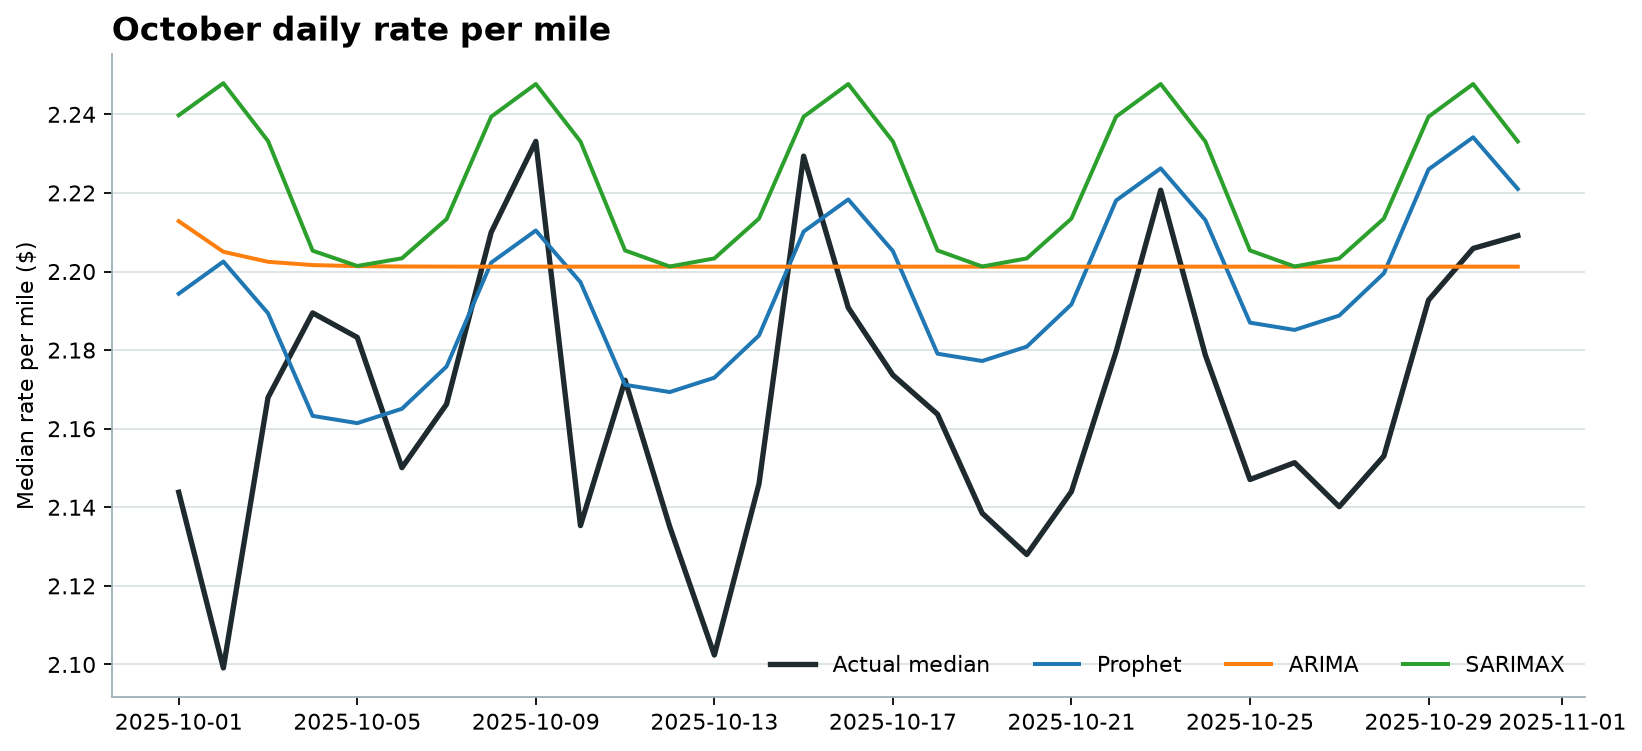

best October MAE: gradient_boosting


In [45]:
keys = {
    "Mileage line": "mileage_baseline",
    "Gradient boosting": "gradient_boosting",
    "Random forest": "random_forest",
    "Prophet": "prophet",
    "ARIMA": "arima",
    "SARIMAX": "sarimax",
}
scored = {keys[row["model"]]: row["october"] for row in scores}
summary = pd.DataFrame([
    {"model": row["model"], "train_mae": row["train"]["mae"], "october_mae": row["october"]["mae"], "train_mape": row["train"]["mape"], "october_mape": row["october"]["mape"]}
    for row in scores
]).set_index("model")
display(summary.round(2))
figure, axis = plt.subplots(figsize=(10, 4.6))
positions = np.arange(len(summary))
axis.bar(positions - 0.18, summary["train_mae"], width=0.36, color="#064A56", label="Training")
axis.bar(positions + 0.18, summary["october_mae"], width=0.36, color="#C46B4A", label="October")
axis.set_xticks(positions, summary.index, rotation=20)
axis.set_ylabel("MAE ($)")
axis.set_title("Training error and October error", loc="left", fontsize=14, fontweight="bold")
axis.legend(frameon=False)
axis.spines[["top", "right"]].set_visible(False)
figure.tight_layout()
save_chart(figure, "All models train versus October")
summary.to_csv(OUTPUT / "model_train_test_scores.csv")
daily = pd.DataFrame({"actual": october_actual, "prophet": prophet_forecast, "arima": arima_forecast, "sarimax": sarimax_forecast})
comparison_charts(scored, daily)
payload = {
    "holdout": "Train on 2025-01-01 through 2025-09-30. Score 2025-10-01 through 2025-10-31.",
    "time_series_note": "Prophet, ARIMA, and SARIMAX forecast the daily median rate per mile. Each October load is priced as forecast rate per mile times an equipment factor from January-September times distance.",
    "models": scored,
    "best_model": min(scored, key=lambda name: scored[name]["mae"]),
}
(OUTPUT / "model_comparison.json").write_text(json.dumps(payload, indent=2), encoding="utf-8")
print("best October MAE:", payload["best_model"])

## Run the checker on the submitted files

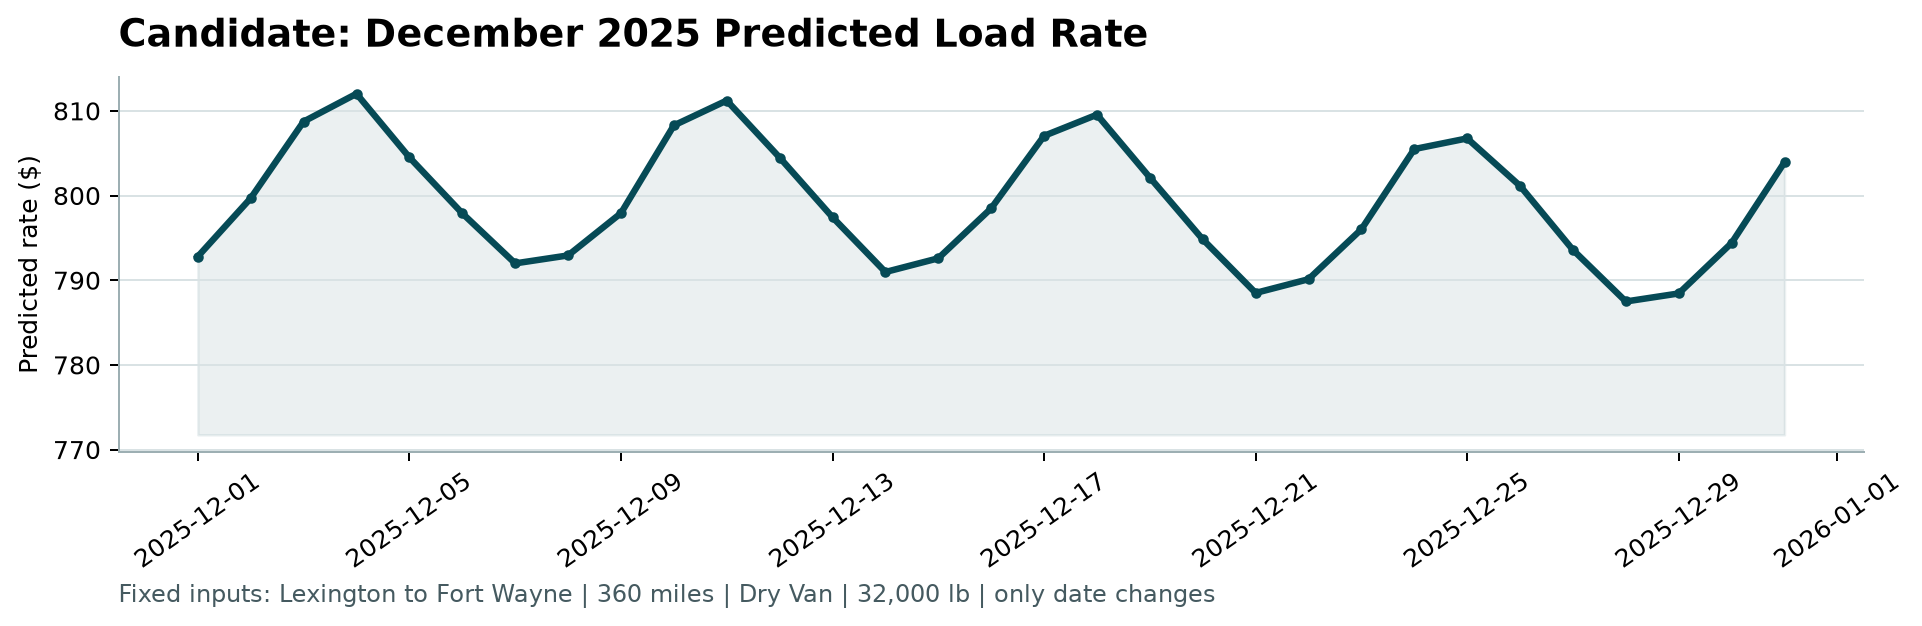

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: d:\projects\SchoolProject\freight-rate-assessment\scorer_results\candidate_december.png
Final validation metrics are calculated by Spotter after submission.


In [46]:
run_scorer(ROOT / "validation_predictions.csv", ROOT / "december_predictions.csv", ROOT / "scorer_results")